In [ ]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black

import sys

scripts_path = "/local/scratch/lslagter/MSC_project/STRW-MSC/scripts"
scripts_path = "/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/scripts"
from pathlib import Path

scripts_path = Path.cwd().parents[1]
if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)

import Config
from Config import (
    CATALOGUE_JEROEN,
    POSITIONS_F115W,
    GAIA_CATALOGUE,
    MPLSTYLE,
    SB_PARAM_DIR,
    PHOT_DIR,
    PLOTS_DIR,
    LEVEL2_DIR,
    LEVEL3_DIR,
    STARBUG2_BIN,
)
import phot_toolkit as PTK
import photometric_pipeline as PPL
import plot_toolkit as PLOT

import numpy as np
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
from astropy.stats import knuth_bin_width
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import astropy.units as u

if MPLSTYLE.exists():
    plt.style.use(str(MPLSTYLE))

working_directory = f"{LEVEL2_DIR}/mastDownload/JWST"
PHOTOMETRIC_pipeline = PPL.Pipeline_level_2_data(working_directory=working_directory)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black
Initialized filepaths for :  ['F187N', 'F335M', 'F115W', 'F277W', 'F200W', 'F444W', 'F182M', 'F430M', 'F090W', 'F356W', 'F150W', 'F480M', 'F212N']


In [12]:
filters = ["F115W"]
modes = ["long", "short"]

pixel_coord_sources = {}
world_coord_sources = {}
magnitudes = {}

for filter in filters:
    pixel_coord_sources[filter] = {}
    world_coord_sources[filter] = {}
    magnitudes[filter] = {}
    for mode in modes:
        (
            pixel_coord_sources[filter][mode],
            world_coord_sources[filter][mode],
            magnitudes[filter][mode],
        ) = PHOTOMETRIC_pipeline._collect_detections_mag_limited(
            filename_ap=f"/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_3/mosaic_{filter}_{mode}_exposure-ap.fits",
            filter=filter,
            detection_sigma=2.0,
        )

Fractional <2.0 Emag 0.7914480012836876
Fractional <2.0 Emag 0.7442652267081178


In [39]:
from astropy.table import Table

psf = Table.read(
    "/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_2/mastDownload/JWST/jw01227002001_02103_00001_nrca1/jw01227002001_02103_00001_nrca1_cal_1overf_jhat-psf.fits"
)
print(len(psf), psf.colnames)


pixel_coord_sources["F115W"]["psf"] = psf["x_fit", "y_fit"]
world_coord_sources["F115W"]["psf"] = psf["RA", "DEC"]

magnitudes["F115W"]["psf"] = psf["F115W", "eF115W"]

15072 ['Catalogue_Number', 'x_init', 'y_init', 'RA', 'DEC', 'ap_F115W', 'flag', 'x_fit', 'y_fit', 'flux', 'eflux', 'xydev', 'qfit', 'F115W', 'eF115W']


In [40]:
catalogue_path = (
    "../Photometry/catalogue_jeroen/NGC346_NIRCam_and_MIRI_Public_JWST_Catalogue.fits"
)
Catalogue = PTK.Read_Catalogue(catalogue_path=catalogue_path).cat_data
Catalogue_ra_dec = SkyCoord(
    ra=Catalogue["RA"] * u.deg, dec=Catalogue["DEC"] * u.deg, frame="icrs"
)

In [16]:
all_matching_idx = []

for mode in modes:
    sc = SkyCoord(
        ra=world_coord_sources[filter][mode][0] * u.deg,
        dec=world_coord_sources[filter][mode][1] * u.deg,
        frame="icrs",
    )
    idx, d2d, _ = sc.match_to_catalog_sky(Catalogue_ra_dec)
    print(len(idx))
    all_matching_idx.append(idx)

all_matching_idx = np.concatenate(all_matching_idx)  # shape: (N_short + N_long,)

971671
1979389


In [41]:
sc = SkyCoord(
    ra=world_coord_sources[filter]["psf"]["RA"] * u.deg,
    dec=world_coord_sources[filter]["psf"]["DEC"] * u.deg,
    frame="icrs",
)
idx, d2d, _ = sc.match_to_catalog_sky(Catalogue_ra_dec)
print(len(idx))
all_matching_idx = idx

15072


With the source coordinates of jeroen where the PSH eMag <2.0 we find with aperture 201.221 with ap eMag <2.0 from the 249.519-47986 = 201.533 in the F115W catalogue 

short -> 113371
long -> 87850

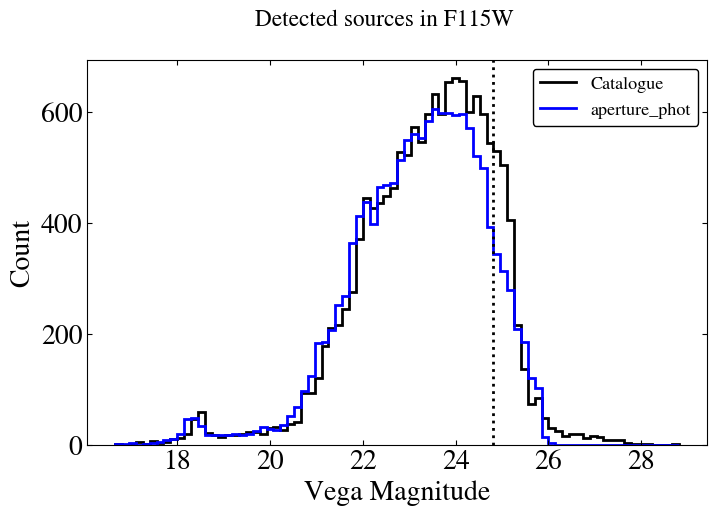

In [49]:
fig = plt.figure()
gs = fig.add_gridspec(1, 1, figure=fig, wspace=0, hspace=0)
ax0 = fig.add_subplot(gs[0, 0])

samples = Catalogue["F115W"][all_matching_idx]

N_samples = len(samples)
dx, bin_edges = knuth_bin_width(samples, return_bins=True)
hist = np.histogram(samples, bins=bin_edges)[0]
ax0.stairs(
    hist,
    edges=bin_edges,
    fill=False,
    label=f"Catalogue",
    lw=2,
    edgecolor="black",
)

# all_mag = np.concatenate((magnitudes[filter]["short"], magnitudes[filter]["long"]))


all_mag = magnitudes[filter]["psf"][filter] - 0.9
all_mag = all_mag[magnitudes[filter]["psf"]["eF115W"] < 0.7]
own_hist = np.histogram(all_mag, bins=bin_edges)[0]
ax0.stairs(
    own_hist,
    edges=bin_edges,
    fill=False,
    label=f"aperture_phot",
    lw=2,
    edgecolor="blue",
)


ax0.legend()
ax0.set_xlabel("Vega Magnitude")
ax0.set_ylabel("Count")

ax0.axvline(x=24.8, label="completeness limit", c="black", lw=2, ls=":")
fig.suptitle(f"Detected sources in F115W ")
plt.show()

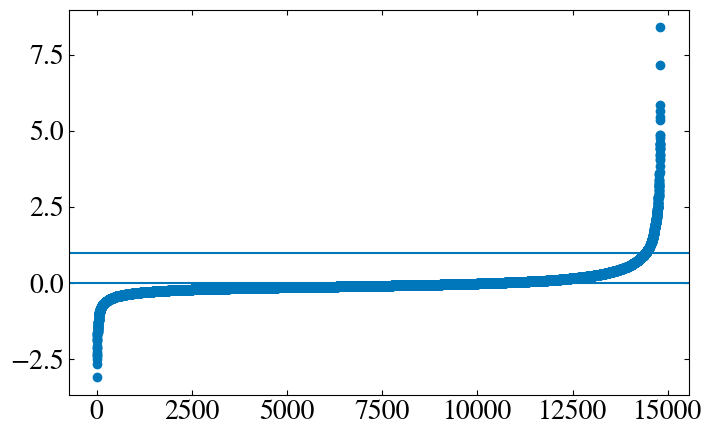

In [48]:
plt.scatter(np.arange(15072), np.sort(all_mag - Catalogue["F115W"][all_matching_idx]))
plt.axhline(1)
plt.axhline(0)